# Notebook for "Under the Canopy: A Methodological Comparison for Computational Motif Analysis in Nineteenth-Century Painting".

This notebook reproduces all figures and tables in the paper. Data loads automatically from HuggingFace ([chcaa/CHR\_detection\_trees](https://huggingface.co/datasets/chcaa/CHR_detection_trees)); a local `segmenttrees_with_masks.parquet` is used as fallback if offline. Run cells top to bottom — each section is self-contained.


In [ ]:
import io, ast, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm
from PIL import Image
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import linregress

warnings.filterwarnings('ignore')

BASE      = os.getcwd()   # set to the project root directory
FIGS      = f'{BASE}/figures'
PQ        = f'{BASE}/segmenttrees_with_masks.parquet'  # local fallback if downloaded separately 

os.makedirs(FIGS, exist_ok=True)

plt.rcParams.update({
    'font.family':        'sans-serif',
    'font.sans-serif':    ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size':          11,
    'axes.spines.top':    False,
    'axes.spines.right':  False,
    'savefig.dpi':        300,
    'savefig.bbox':       'tight',
})
print('Setup complete.')

Setup complete.


In [ ]:
# Colour constants used across all figures
COLOR_BAR  = '#028090'   # main bar / fill colour  
COLOR_LINE = '#165054'   # accent / line colour    

## data and preprocessing

Loads the corpus from HuggingFace (or a local parquet fallback). Each row represents one painting. Key columns:

- `has_tree` — boolean, whether SAM3 detected at least one tree
- `count` — number of tree instances detected
- `mask` — bytes-encoded NPZ file containing the boolean segmentation masks (shape `n_trees × 1 × H × W`)
- `image` — JPEG bytes of the painting
- `Artist-nationality` — assigned via the `CATEGORIES` dictionary below
- `year` / `decade` — production date (408 paintings have no date)


In [ ]:
def parse_list(v):
    if isinstance(v, list): return v
    try:    return ast.literal_eval(v)
    except: return []

# Load corpus — local file first, HuggingFace as fallback
import os
if os.path.exists(PQ):
    df = pd.read_parquet(PQ)
    print('Loaded from local file.')
else:
    from datasets import load_dataset
    df = load_dataset('chcaa/CHR_detection_trees', split='train').to_pandas()
    print('Loaded from HuggingFace: chcaa/CHR_detection_trees')
df['boxes']  = df['boxes'].apply(parse_list)
df['scores'] = df['scores'].apply(parse_list)

# parse inception
raw_inception = df['inception'].copy()   # save original strings before converting
df['inception'] = pd.to_datetime(df['inception'], errors='coerce')
df['year']      = df['inception'].dt.year

# Recover rows where datetime parse failed but raw value is a 4-digit year string
fallback_mask = df['year'].isna() & raw_inception.notna()
df.loc[fallback_mask, 'year'] = pd.to_numeric(raw_inception[fallback_mask], errors='coerce')
df = df[df['year'].isna() | df['year'].between(1800, 1910)].copy().reset_index(drop=True)
df['has_tree'] = df['count'] > 0
df['decade']   = (df['year'] // 10) * 10

yr = df['year'].dropna()
print(f'Corpus (1800-1910 or undated): {len(df):>6,} paintings')
print(f'Year range (dated):            {int(yr.min())} - {int(yr.max())}')
print(f'Undated paintings:             {df["year"].isna().sum():>6,}')
print(f'With >= 1 tree detected:       {df["has_tree"].sum():>6,} ({df["has_tree"].mean():.1%})')
print(f'Total tree instances:          {df["count"].sum():>6,}')


README.md:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

data/train-00000-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00000-of-00006.parquet: downloading bytes:           |  0.00B            

0.05s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


data/train-00001-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  890MB            

data/train-00001-of-00006.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

data/train-00005-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  434MB            

data/train-00005-of-00006.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4727 [00:00<?, ? examples/s]

Loaded from HuggingFace: chcaa/CHR_detection_trees
Corpus (1800-1910 or undated):  4,633 paintings
Year range (dated):            1800 - 1910
Undated paintings:              1,004
With >= 1 tree detected:        2,920 (63.0%)
Total tree instances:          26,418


In [ ]:
#predefine colours for nationality
CATEGORIES = {
    "Norwegian": {
        "color": "#028090",
        "artists": ["Asta Hansteen", "August Schneider", "Johann Christian Dahl", "Carl Nielsen", "Edvard Diriks", "Edvard Otto Rossing Skari", "Frits Thaulow", "Georg Anton Rasmussen", "Georg Fredrik Holter", "Haldor Hjerleid", "Hedevig Lund", "Johan Jørgen Broch", "Johan Ludvig Losting", "Ludvig Skramstad", "Magnus Thulstrup Bagge", "Marcus Grønvold", "Mathias Wilhelm Eckhoff", "Otto Sinding", "Peder Cappelen Thurmann", "Peter Nicolai Arbo", "Peter Petersen", "Philip Barlag", "Sophus Jacobsen", "Frederik Petersen", "Gerhard Munthe", "Johan Gørbitz", "Johan Jacob Bennetter", "Johannes Martin Grimelund", "Kitty Kielland", "Mikkel Pettersson Mandt", "Olaf Dahl", "Olaf Isaachsen", "Reinholdt Boll", "Thorben Viking Bille", "Tycho Jæger", "Christian Due", "Anton Bergh", "Carl Schøyen", "Jacob Munch", "Niels Bjørnsen Møller", "Christian Wexelsen", "Ferdinand Gjøs", "Frants Diderik Bøe", "Jacob Calmeyer", "Matthias Stoltenberg", "Knud Geelmuyden Bull", "Ludvig Munthe", "Andreas Edvard Disen", "Gustav Adolph Mordt", "Bernt Lund", "Johan Martin Nielssen", "Morten Müller", "Erik Bodom", "Lars Hertervig", "Adolph Tidemand", "Joachim Frich", "Johan Fredrik Eckersberg", "August Cappelen", "Frederik Collett", "Anders Askevold", "Amaldus Nielsen", "Peder Balke", "Knud Baade", "Thomas Fearnley", "Hans Gude", "Thomas Joachim Legler", "Heinrich Grosch", "Hans Ditlev Frantz von Linstow", "Johannes Flintoe", "Betzy Akersloot-Berg"],
    },
    "Danish": {
        "color": "#165054",  
        "artists": ["A. E. Kieldrup", "Anders Christian Lunde", "Andreas Juuel", "Andreas Riis Castensen", "Anthon Christoffer Rüde", "Anton Dorph", "Anton Melbye", "August Wilhelm Boesen", "Bolette Puggaard", "C. Eckardt", "C.A. Kølle", "Carl Anton Saabye", "Carl Bille", "Carl Bloch", "Carl Bøgh", "Carl Dahl", "Carl Emil Baagøe", "Carl Frederik Aagaard", "Carl Frederik Sørensen", "Carl Frederik Vogt", "Carl Georg Scheuermann", "Carl Neumann", "Carl Otto Haslund", "Carlo Dalgas", "Christen Dalsgaard", "Christen Købke", "Christian August Lorentzen", "Christian Blache", "Christian David Gebauer", "Christian Zacho", "Christoffer Wilhelm Eckersberg", "Constantin Hansen", "Dankvart Dreyer", "David Jacobsen", "Eiler Rasmussen Eilersen", "Elias Meyer", "Emanuel Larsen", "Emil Normann", "Erik Pauelsen", "Ernst Meyer", "F. C. Kiaerskou", "Ferdinand Richardt", "Frederik Hansen Sødring", "Frederik Kraft", "Frederik Rohde", "Frederik Vermehren", "Friedrich Thøming", "Frits Grove", "Fritz Petzholdt", "Georg Emil Libert", "Godfred Christensen", "Godtfred Rump", "Gudrun Poulsen", "H.J. Hammer", "H.J. Paludan", "H.W. Bissen", "Hans Friis", "Hans Smidth", "Harald Foss", "Heinrich Buntzen", "Henrich Christian From", "I. E. C. Rasmussen", "J.P. Møller", "Jacob Petersen", "Janus la Cour", "Jens Juel", "Johan Ludvig Lund", "Johan Stroe", "Johan Thomas Lundbye", "Jørgen Roed", "Jørgen V. Sonne", "Julie Lütken", "Julius Hellesen", "Just Jerndorff", "Lorenz Frølich", "Madsen, A.P.", "Martinus Rørbye", "Niels Simonsen", "Otto Bache", "P. C. Skovgaard", "Peter Cramer", "Peter Raadsig", "Samuel Mygind", "Theodor Philipsen", "Thorald Brendstrup", "Thorald Læssøe", "Thorvald Niss", "Ulrich Baudissin", "Vilhelm Groth", "Vilhelm Kyhn", "Vilhelm Melbye", "Vilhelm Petersen", "Wilhelm Bendz", "Wilhelm Xylander"],
    },
    "Swedish": {
        "color": "#7ecec4",  
        "artists": ["Alexander Wetterling", "Alfred Wiström", "Anders Hansson Kallenberg", "August Malmström", "Carl August Fahlgren", "Carl Ferdinand Hernlund", "Ernfried Wahlqvist", "Gustaf Söderberg", "Josefina Holmlund", "Julius Kronberg", "Nils Schillmark", "Oskar Emil Törnå", "Oskar Leonard Anderson", "Per Daniel Holm", "Per Gustaf von Heideken", "Axel Nordgren", "Carl Peter Lehmann", "Carl Stefan Bennet", "Evelina Stading", "Karl XV av Sverige og Norge", "Lars Theodor Billing", "Pehr Nordquist", "Tore Billing", "Wilhelm Maximilian Carpelan", "Johan Christian Berger", "Gustaf Rydberg", "Joseph Magnus Stäck", "Marcus Larson", "Nils Jakob Olsson Blommér", "Johan Edvard Bergh", "Per Ekström", "Elias Martin", "Olof Hermelin", "Gustaf Palm", "Carl Johan Fahlcrantz"],
    },
    "Finnish": {
        "color": "#b8e8e4", 
        "artists": ["Ada Thilén", "Emilia Appelgren", "Pehr Adolf Kruskopf", "Thorsten Waenerberg", "Oscar Kleineh", "Fredrik Ahlstedt", "Alexander Lauréus", "Adolf von Becker", "Ida Silfverberg", "Lennart Forstén", "Augusta Soldan", "Emma Gylden", "Amélie Lundahl", "Victoria Åberg", "Ferdinand von Wright", "Albert Edelfelt", "Johan Knutson", "Hjalmar Munsterhjelm", "Fanny Churberg", "Werner Holmberg", "Ulrik Thersner", "Robert Wilhelm Ekman", "Magnus von Wright", "Berndt Lindholm"],
    },
    "German, Austrian and Swiss": {
        "color": "#cccccc",  
        "artists": ["Caspar David Friedrich", "Eduard Peithner von Lichtenfels", "Josef Willroider", "Franz Richard Unterberger", "Friedrich Loos", "Adolf Carl", "Christian Fredrik Gille", "Emil Wolff", "Georg Köster", "Michael Emil Sachs", "Carl Hilgers", "Carl Morgenstern", "Eugen Krüger", "August Kessler", "Ludwig Scheins", "Adam Müller", "Adolf Mosengel", "Charles Ross", "Edward C. Post", "Eugen Friedrich Peipers", "Fritz Hildebrandt", "Hermann Kauffmann", "Hermann Mevius", "Jacob Wilhelm Mechau", "Joachim Bünsow", "Joseph Anton Koch", "Julius Kornbeck", "Karl Julius von Leypold", "Karl Millner", "Lina von Perbandt", "Wilhelm Porttmann", "Anton Dieffenbach", "Hermann Both", "Johann Friedrich Weitsch", "Albert Berg", "Johann Siegwald Dahl", "Hermann Carmiencke", "Bernhard Fries", "Christian Ezdorf", "Wilhelm Brandenburg", "Ascan Lutteroth", "Antonie Biel", "Eduard Leonhardi", "Valentin Ruths", "Friedrich Theodore Kloss", "Richard Freytag", "Ernst Fries", "Johann Baptist Kirner", "August Becker", "Georg Friedrich Kersting", "Ernst Willers", "Adolph Friedrich Vollmer", "Christian Morgenstern", "Anton Teichlein", "Johann Mohr", "Heinrich Vosberg", "Charles Feodor Welsch", "Alexander Michelis", "Arnold Schulten", "August Wilhelm Leu", "Carl Wilhelm Hübner", "Georg Eduard Otto Saal", "Leonhard Rausch", "Carl Jungheim", "Eduard Wilhelm Pose", "Heinrich Funk", "Franz Ludwig Catel", "Johann Wilhelm Lindlar", "Karl Friedrich Schulz", "Paul Franken", "Adolf Schreyer", "Albert Arnz", "Karl Friedrich Lessing", "Johann Wilhelm Schirmer", "Oswald Achenbach", "Andreas Achenbach", "Louis Gurlitt", "Curt Victor Clemens Grolig", "Ernst Ferdinand Oehme", "Gustav Friedrich Papperitz", "Johann Christian Klengel", "Ludwig Richter", "Carl Gustav Carus", "Friedrich Simmler", "Carl Maria Nicolaus Hummel"],
    },
    "British": {
        "color": "#555555", 
        "artists": ["John Constable", "J. M. W. Turner"],
    },
}

# Build reverse mapping: artist name to category label
artist_to_nat = {artist: nat for nat, info in CATEGORIES.items() for artist in info['artists']}

# Overwrite Artist-nationality where we have information: keep existing value otherwise
df['Artist-nationality'] = df['artist'].map(artist_to_nat).fillna(df['Artist-nationality'])

print('Nationality coverage after mapping:')
print(df['Artist-nationality'].value_counts(dropna=False).to_string())
print(f'\nMapped:   {df["Artist-nationality"].notna().sum():,} / {len(df):,} paintings')
print(f'Unmapped: {df["Artist-nationality"].isna().sum():,}')
# Derived lists used throughout the notebook
col_order = list(CATEGORIES.keys())                          # nationality order
colors    = [CATEGORIES[n]['color'] for n in col_order]      # matching colours
top_nats  = col_order                                         # alias used in grouped bar
nat_colors = {n: CATEGORIES[n]['color'] for n in col_order}  # dict lookup


Nationality coverage after mapping:
Artist-nationality
Danish                                               1305
Norwegian                                            1206
German, Austrian and Swiss                            798
British                                               787
Finnish                                               306
Swedish                                               133
None                                                   66
fransk                                                  7
['Amerikansk']                                          2
flamländsk                                              1
brittisk                                                1
svensk                                                  1
[None]                                                  1
['Fransk']                                              1
['Hollandsk', 'Hollandsk', 'Flamsk', 'Hollandsk']       1

Mapped:   4,550 / 4,616 paintings
Unmapped: 66


## spatial metrics

Reads the boolean masks from the `mask` column. Each mask is an NPZ array with shape `(n_trees, 1, H, W)`. For each painting we compute

- **Occupancy** — share of canvas covered by tree pixels
- **Centroid x/y** — average horizontal and vertical position of each detected tree


In [41]:
# Compute occupancy and centroid coordinates from the embedded mask column.
# Only processes paintings with detected trees.
mask_data = {}   # df index -> {occupancy, cxs, cys}

tree_df    = df[df['has_tree']]
mask_col   = tree_df['mask']        # extract column upfront to avoid name conflicts
print(f'Computing spatial metrics for {len(tree_df):,} tree paintings...')

for i, idx in enumerate(tree_df.index):
    if i % 500 == 0: print(f'  {i:,} / {len(tree_df):,}')
    mask_bytes = mask_col.at[idx]
    if not isinstance(mask_bytes, (bytes, bytearray)) or len(mask_bytes) == 0:
        mask_data[idx] = {'occupancy': 0.0, 'cxs': [], 'cys': []}
        continue
    try:
        npz   = np.load(io.BytesIO(mask_bytes), allow_pickle=True)
        masks = npz['masks']
        if masks.ndim != 4 or masks.shape[0] == 0:
            mask_data[idx] = {'occupancy': 0.0, 'cxs': [], 'cys': []}
            continue
        n, _, H, W = masks.shape
        union     = masks[:, 0].any(axis=0)
        occupancy = float(union.sum()) / (H * W)
        cxs, cys  = [], []
        for k in range(n):
            m = masks[k, 0]
            if m.any():
                ry, rx = np.where(m)
                cys.append(ry.mean() / H)
                cxs.append(rx.mean() / W)
        mask_data[idx] = {'occupancy': occupancy, 'cxs': cxs, 'cys': cys}
    except:
        mask_data[idx] = {'occupancy': np.nan, 'cxs': [], 'cys': []}

print(f'Done. Computed metrics for {len(mask_data):,} paintings.')


Computing spatial metrics for 2,905 tree paintings...
  0 / 2,905
  500 / 2,905
  1,000 / 2,905
  1,500 / 2,905
  2,000 / 2,905
  2,500 / 2,905
Done. Computed metrics for 2,905 paintings.


In [42]:
# Merge spatial metrics back into df
df['mask_occupancy'] = df.index.map(
    lambda i: mask_data.get(i, {}).get('occupancy', np.nan)
)

# Build per-tree centroid dataframe (one row per detected tree instance)
centroid_rows = []
for idx, row in df.iterrows():
    md = mask_data.get(idx, {})
    for cx, cy in zip(md.get('cxs', []), md.get('cys', [])):
        centroid_rows.append({
            'year': row['year'], 'decade': row['decade'],
            'artist': row['artist'], 'cx': cx, 'cy': cy
        })

df_cents = pd.DataFrame(centroid_rows)
print(f'Total individual tree centroids: {len(df_cents):,}')
print(f'mask_occupancy available for:   {df["mask_occupancy"].notna().sum():,} paintings')


Total individual tree centroids: 26,259
mask_occupancy available for:   2,905 paintings


## corpus

Summary statistics for the full corpus


In [ ]:
total      = len(df)
n_trees    = int(df['has_tree'].sum())
n_inst     = int(df['count'].sum())
share      = n_trees / total

table1 = pd.DataFrame([
    ('Total number of images',              f'{total:,}'),
    ('Images with at least one tree',       f'{n_trees:,}'),
    ('Total number of tree instances',      f'{n_inst:,}'),
    ('Share of images with trees',          f'{share:.1%}'),
], columns=['Metric', 'Value'])

display(table1.to_string(index=False))

'                        Metric  Value\n        Total number of images  4,616\n Images with at least one tree  2,905\nTotal number of tree instances 26,259\n    Share of images with trees  62.9%'

### testing output

Six paintings shown with their detected tree count, one per target artist


In [ ]:
TARGET_ARTISTS = [
    'Caspar David Friedrich', 'Johann Christian Dahl', 'Dankvart Dreyer',
    'Thomas Fearnley', 'Louis Gurlitt', 'Vilhelm Kyhn'
]

# Collect one series per target artist
ex_rows = []
for artist in TARGET_ARTISTS:
    sub = df[(df['artist'] == artist) & df['has_tree']]
    if len(sub) > 0:
        ex_rows.append(sub.iloc[0])

# Fill remaining slots if some artists arent found
if len(ex_rows) < 6:
    seen = {r['artist'] for r in ex_rows}
    for _, row in df[df['has_tree']].iterrows():
        if len(ex_rows) >= 6:
            break
        if row['artist'] not in seen:
            ex_rows.append(row)
            seen.add(row['artist'])

table2 = []
for row in ex_rows:
    sc = row['scores'] or []
    bx = row['boxes']  or []
    fname = os.path.basename(str(row.get('image_filename') or row.get('filename', '')))
    table2.append({
        'Artist':         row['artist'],
        'H × W':          f"{row['original_height']} × {row['original_width']}",
        'Scores (trunc)': [round(s, 2) for s in sc[:3]],
        'Boxes (first)':  [[round(v, 1) for v in bx[0]]] if bx else [],
        'Count':          row['count'],   
        'Filename':       fname[:35],
    })

pd.DataFrame(table2)

,Artist,H × W,Scores (trunc),Boxes (first),Count,Filename
0,Caspar David Friedrich,850 × 655,"[0.71, 0.4, 0.56]","[[464.8, 291.4, 527.6, 569.9]]",6,Aurora_boreal_-_Caspar_David_Friedr
1,Johann Christian Dahl,640 × 1500,"[0.48, 0.42, 0.42]","[[410.0, 402.3, 431.4, 424.9]]",14,'From_Bergen_Harbor'_by_Johan_Chris
2,Dankvart Dreyer,976 × 1500,"[0.42, 0.63, 0.88]","[[465.8, 3.6, 736.8, 236.7]]",3,"Dankvart_Dreyer,_Bro_over_kirkegård"
3,Thomas Fearnley,1102 × 1500,"[0.48, 0.57, 0.49]","[[758.2, 323.0, 883.7, 624.8]]",8,'Hunting_at_Königsee'_by_Thomas_Fea
4,Louis Gurlitt,1500 × 1333,"[0.71, 0.6, 0.68]","[[1109.8, 58.4, 1154.1, 147.1]]",12,1835_Gurlitt_Wasserfall_in_Norwegen
5,Vilhelm Kyhn,1100 × 1500,[0.79],"[[826.6, 220.1, 1368.8, 721.8]]",1,Aftenstemning_(Vilhelm_Kyhn_-_1861)


## test artist

Aggregates detection data to the artist level

In [ ]:
artist_stats = (
    df.groupby('artist')
      .agg(with_trees=('has_tree', 'sum'), total=('has_tree', 'count'))
      .assign(share=lambda d: d['with_trees'] / d['total'])
      .reset_index()
)

# Top 10 by absolute count
top10_abs = (
    artist_stats.nlargest(10, 'with_trees')
    .assign(share=lambda d: d['share'].map('{:.1%}'.format))
    .rename(columns={'artist': 'Artist', 'with_trees': 'Paintings with trees',
                     'total': 'Total paintings', 'share': 'Share'})
)
print('Top 10 by absolute count:')
display(top10_abs[['Artist','Paintings with trees','Total paintings','Share']].to_string(index=False))

# Top 10 normalized (≥5 paintings, sorted by share)
top10_norm = (
    artist_stats[artist_stats['total'] >= 5]
    .nlargest(10, 'share')
    .assign(share=lambda d: d['share'].map('{:.1%}'.format))
    .rename(columns={'artist': 'Artist', 'with_trees': 'Paintings with trees',
                     'total': 'Total paintings', 'share': 'Share'})
)
print('\nTop 10 normalized (≥5 paintings):')
display(top10_norm[['Artist','Paintings with trees','Total paintings','Share']].to_string(index=False))

Top 10 by absolute count:


'                Artist  Paintings with trees  Total paintings Share\n        John Constable                   335              442 75.8%\n Johann Christian Dahl                   257              428 60.0%\n       J. M. W. Turner                   152              345 44.1%\n Carl Frederik Aagaard                   123              172 71.5%\nCaspar David Friedrich                    97              159 61.0%\n         Janus la Cour                    90              160 56.2%\n       P. C. Skovgaard                    85              102 83.3%\n     Andreas Achenbach                    71              139 51.1%\n             Hans Gude                    71              127 55.9%\n       Thomas Fearnley                    69              109 63.3%'


Top 10 normalized (≥5 paintings):


'                    Artist  Paintings with trees  Total paintings  Share\n        Carl Frederik Vogt                     7                7 100.0%\nChristian August Lorentzen                     9                9 100.0%\n   Christian David Gebauer                     5                5 100.0%\n               Elias Meyer                     8                8 100.0%\n          Fredrik Ahlstedt                     6                6 100.0%\n    Henrich Christian From                     6                6 100.0%\n               J.P. Møller                     8                8 100.0%\n               Johann Mohr                     6                6 100.0%\n         Magnus von Wright                     9                9 100.0%\n            Victoria Åberg                     8                8 100.0%'

## test paintings


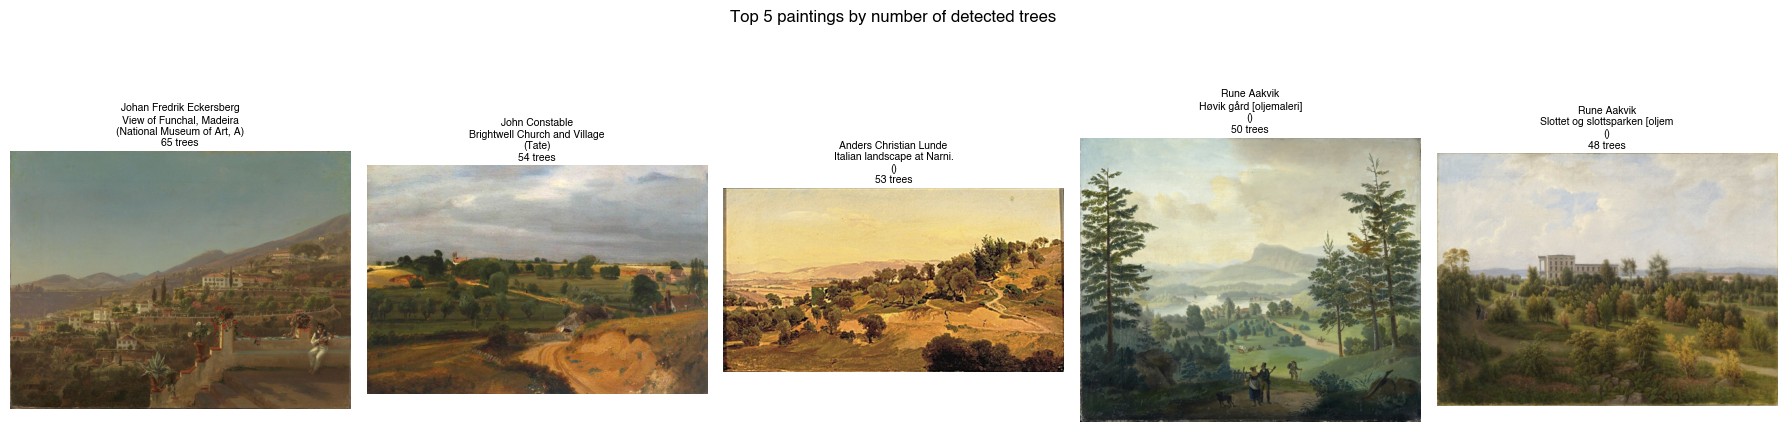

In [ ]:
top5 = df.nlargest(5, 'count')[['title','artist','collection','count','image']].reset_index(drop=True)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, (_, row) in zip(axes, top5.iterrows()):
    img = Image.open(io.BytesIO(row['image']))
    img.thumbnail((500, 500))
    ax.imshow(img)
    # make long titles/collections smaller
    title  = (row['title']  or '')[:30]
    artist = (row['artist'] or '')[:25]
    coll   = (row['collection'] or '')[:25]
    ax.set_title(f"{artist}\n{title}\n({coll})\n{row['count']} trees",
                 fontsize=7.5, pad=4)
    ax.axis('off')

plt.suptitle('Top 5 paintings by number of detected trees', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(f'{FIGS}/fig4_top5_paintings.pdf')
plt.show()

## diachronic

How does tree prevalence change over time

1. **Decade-level frequency** — share of paintings with trees per decade
2. **Nationality breakdown per decade** — detection rate within each national school
3. **Artist-level stacked bar** — how many artists painted trees vs. did not, per decade



In [ ]:
# Decade-level aggregates
df_trees = df[df['has_tree']].copy()

total_dec    = df.groupby('decade').size().rename('n_total')
tree_img_dec = df_trees.groupby('decade').size().rename('n_tree_imgs')
tree_ins_dec = df_trees.groupby('decade')['count'].sum().rename('n_instances')

dec = (
    pd.concat([total_dec, tree_img_dec, tree_ins_dec], axis=1)
      .reset_index()
      .sort_values('decade')
)
dec['share']       = dec['n_tree_imgs'] / dec['n_total']
dec['density']     = dec['n_instances'] / dec['n_tree_imgs']   # avg trees per tree painting
dec['share_sm']    = dec['share'].rolling(3, center=True, min_periods=2).mean()
dec['density_sm']  = dec['density'].rolling(3, center=True, min_periods=2).mean()

print('Decade table:')
display(dec[['decade','n_total','n_tree_imgs','n_instances','share','density']]
        .rename(columns={'n_total':'total','n_tree_imgs':'w/trees','n_instances':'instances',
                         'share':'share','density':'avg trees/painting'})
        .to_string(index=False))

Decade table:


' decade  total  w/trees  instances    share  avg trees/painting\n 1800.0    179      136       1323 0.759777            9.727941\n 1810.0    273      208       1995 0.761905            9.591346\n 1820.0    530      316       2439 0.596226            7.718354\n 1830.0    546      316       2623 0.578755            8.300633\n 1840.0    511      299       3006 0.585127           10.053512\n 1850.0    526      357       3425 0.678707            9.593838\n 1860.0    343      221       2069 0.644315            9.361991\n 1870.0    480      294       2323 0.612500            7.901361\n 1880.0    319      179       1276 0.561129            7.128492\n 1890.0    161       92        751 0.571429            8.163043\n 1900.0     75       41        289 0.546667            7.048780\n 1910.0      3        2         25 0.666667           12.500000'

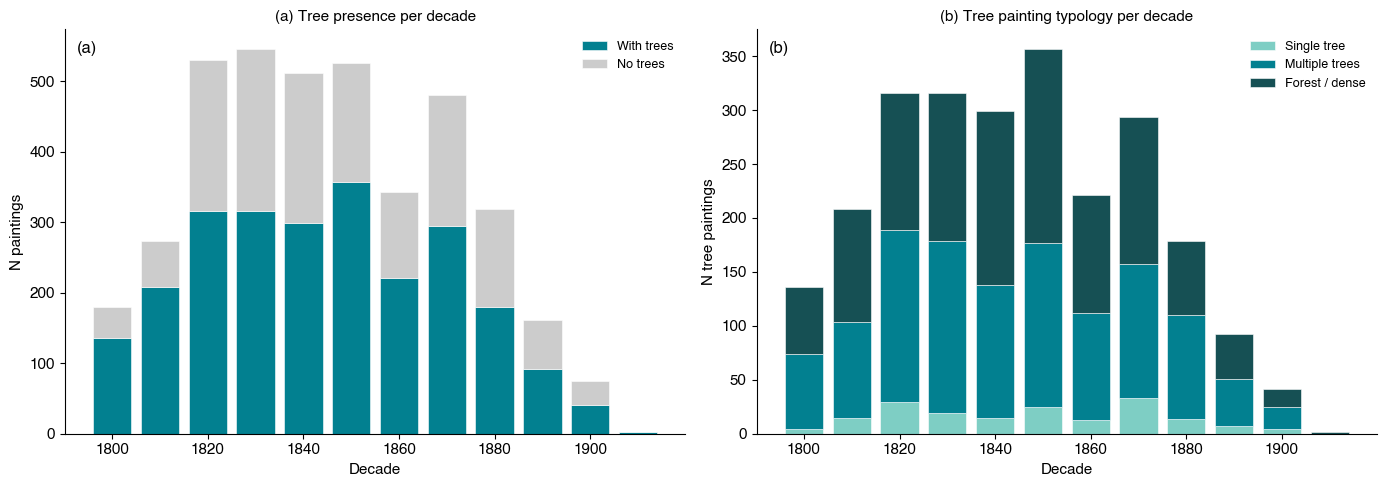

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# tree vs no-tree paintings per decade
ax1 = axes[0]

n_tree    = dec['n_tree_imgs']
n_no_tree = dec['n_total'] - dec['n_tree_imgs']

ax1.bar(dec['decade'], n_tree,    width=8, color=COLOR_BAR, ec='white', lw=0.4,
        label='With trees')
ax1.bar(dec['decade'], n_no_tree, width=8, color='#cccccc', ec='white', lw=0.4,
        bottom=n_tree, label='No trees')

ax1.set_ylabel('N paintings', fontsize=11)
ax1.set_xlabel('Decade', fontsize=11)
ax1.set_title('(a) Tree presence per decade', fontsize=11)
ax1.legend(fontsize=9, frameon=False)
ax1.text(0.02, 0.97, '(a)', transform=ax1.transAxes, fontsize=12, va='top', fontweight='bold')


plt.tight_layout()
plt.savefig(f'{FIGS}/fig5_diachronic.pdf')
plt.show()

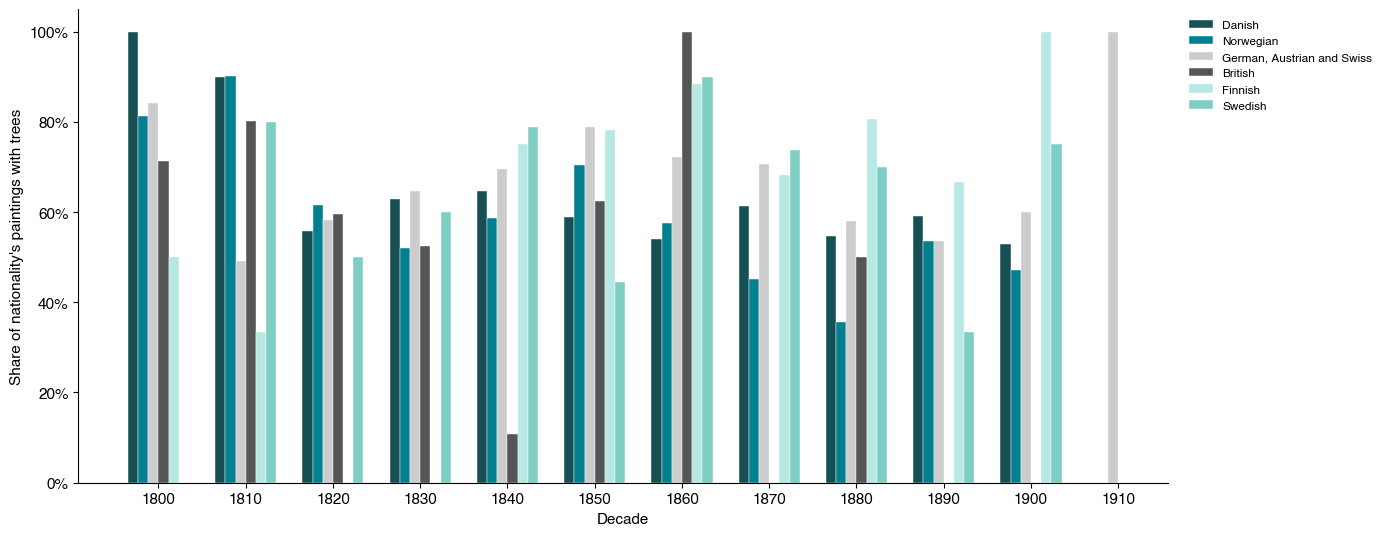

In [ ]:
# Grouped bar: share of each nationality's own paintings with trees per decade

# Count total paintings and tree paintings per decade and nationality
nat_dec_all = (
    df[df['year'].notna() & df['Artist-nationality'].isin(top_nats)]
    .groupby(['decade', 'Artist-nationality'])
    .agg(n_total=('has_tree', 'count'),   
         n_tree =('has_tree', 'sum'))      
    .reset_index()
)
# Share = tree paintings / all paintings within each nationality
nat_dec_all['share'] = nat_dec_all['n_tree'] / nat_dec_all['n_total']

decades   = sorted(nat_dec_all['decade'].unique())
n_nats    = len(col_order)
bar_width = 7 / n_nats   # total decade width split evenly across nationalities
offsets   = np.linspace(-(n_nats - 1) / 2, (n_nats - 1) / 2, n_nats) * bar_width

fig, ax = plt.subplots(figsize=(14, 5.5))

# Draw one set of bars per nationality
for i, (nat, color) in enumerate(zip(col_order, colors)):
    #  NaN where no data
    grp  = nat_dec_all[nat_dec_all['Artist-nationality'] == nat].set_index('decade')
    vals = [grp.loc[d, 'share'] if d in grp.index else np.nan for d in decades]
    ax.bar([d + offsets[i] for d in decades], vals, width=bar_width,
           color=color, label=nat, edgecolor='white', linewidth=0.3)

ax.set_xlabel('Decade', fontsize=11)
ax.set_ylabel("Share of nationality's paintings with trees", fontsize=11)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_xticks(decades)
ax.legend(fontsize=8.5, bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)

plt.tight_layout()
plt.savefig(f'{FIGS}/fig_nationality_grouped.pdf')
plt.show()


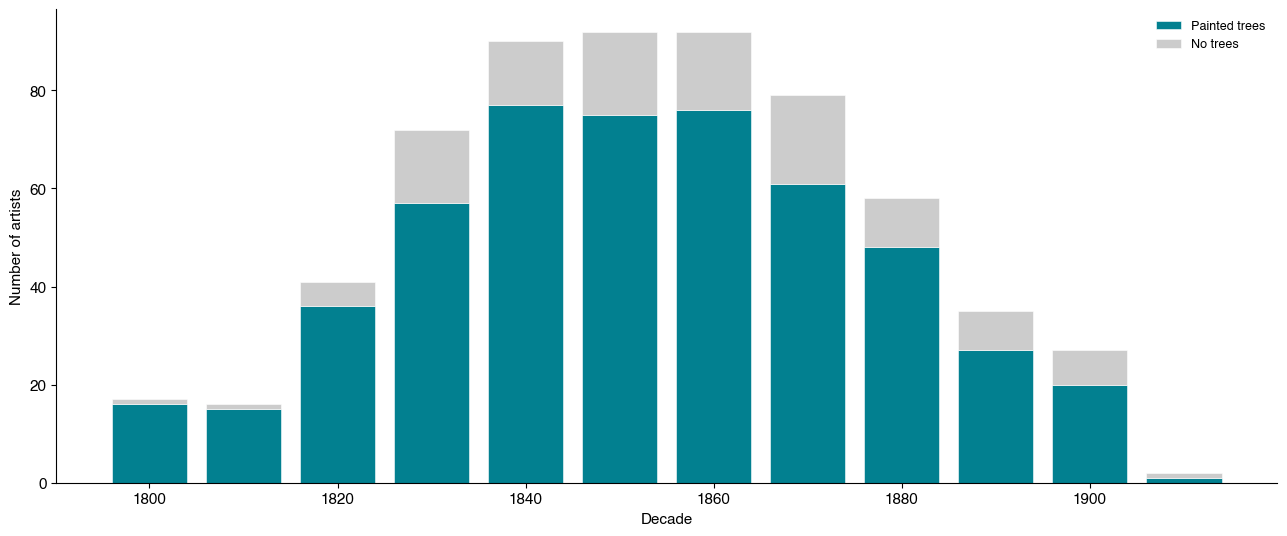

In [ ]:
# Artist-level stacked bar
artist_dec = (
    df[df['year'].notna()]
    .groupby(['decade', 'artist'])
    .agg(has_any_tree=('has_tree', 'any'))
    .reset_index()
)
dec_artist = (
    artist_dec.groupby('decade')
    .agg(n_tree_artists=('has_any_tree', 'sum'),
         n_total_artists=('artist', 'count'))
    .reset_index()
)
dec_artist['n_no_tree'] = dec_artist['n_total_artists'] - dec_artist['n_tree_artists']

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.bar(dec_artist['decade'], dec_artist['n_tree_artists'], width=8,
       color=COLOR_BAR, edgecolor='white', linewidth=0.4, label='Painted trees')
ax.bar(dec_artist['decade'], dec_artist['n_no_tree'], width=8,
       bottom=dec_artist['n_tree_artists'],
       color='#cccccc', edgecolor='white', linewidth=0.4, label='No trees')

ax.set_xlabel('Decade', fontsize=11)
ax.set_ylabel('Number of artists', fontsize=11)
ax.set_title('', fontsize=11)
ax.legend(fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig(f'{FIGS}/fig_artist_level_diachronic.pdf')
plt.show()


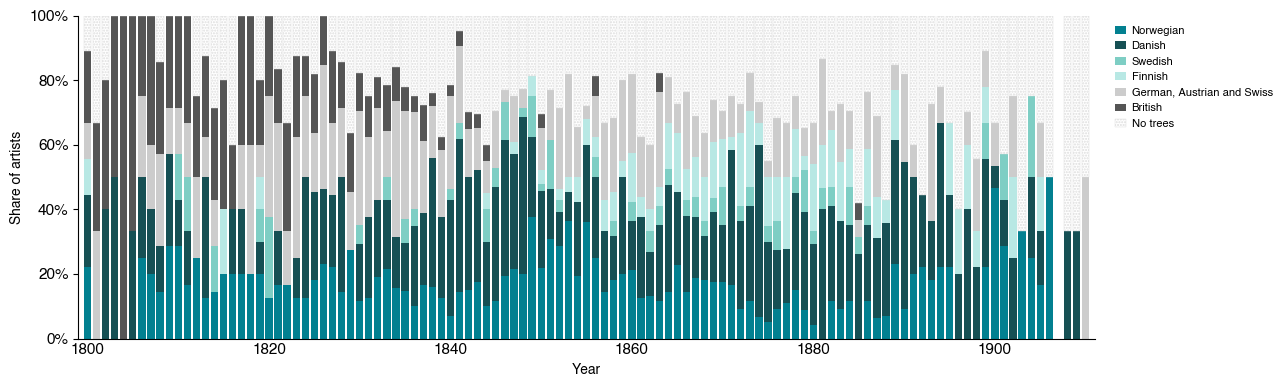

In [ ]:
#full stacked bar: tree painters by nationality + no-tree artists, year by year
df_dated = df[df['year'].notna()].copy()
df_dated['year'] = df_dated['year'].astype(int)

# one row per artist per year
artist_yr = (
    df_dated
    .groupby(['year', 'artist'])
    .agg(nat=('Artist-nationality', 'first'),
         painted_tree=('has_tree', 'any'))
    .reset_index()
)

nat_order  = list(CATEGORIES.keys())
nat_colors = {k: v['color'] for k, v in CATEGORIES.items()}

tree_counts = (
    artist_yr[artist_yr['painted_tree']]
    .groupby(['year', 'nat'])
    .size()
    .reset_index(name='n')
)
notree_counts = (
    artist_yr[~artist_yr['painted_tree']]
    .groupby('year')
    .size()
    .reset_index(name='no_tree')
)

pivot = tree_counts.pivot_table(
    index='year', columns='nat', values='n', fill_value=0
).reset_index()
pivot = pivot.merge(notree_counts, on='year', how='left').fillna(0)

nat_cols = [n for n in nat_order if n in pivot.columns]
all_cols  = nat_cols + ['no_tree']

row_totals = pivot[all_cols].sum(axis=1)
pivot_pct  = pivot.copy()
for col in all_cols:
    pivot_pct[col] = pivot[col] / row_totals * 100

fig, ax = plt.subplots(figsize=(13, 4))
years  = pivot_pct['year'].values
bottom = np.zeros(len(years))

for nat in nat_cols:
    ax.bar(years, pivot_pct[nat], bottom=bottom, width=0.8,
           color=nat_colors.get(nat, '#aaaaaa'), edgecolor='none', label=nat)
    bottom += pivot_pct[nat].values

ax.bar(years, pivot_pct['no_tree'], bottom=bottom, width=0.8,
       color='white', edgecolor='#dddddd', hatch='......', linewidth=0.3, label='No trees')

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: str(int(y)) + '%'))
ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Share of artists', fontsize=10)
ax.set_xlim(years.min() - 1, years.max() + 1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', length=0)
ax.legend(frameon=False, fontsize=8,
          bbox_to_anchor=(1.01, 1), loc='upper left',
          handlelength=1, handletextpad=0.5)

plt.tight_layout()
plt.savefig('fig_nat_tree_norm_yearly.pdf', dpi=150, bbox_inches='tight')
plt.show()


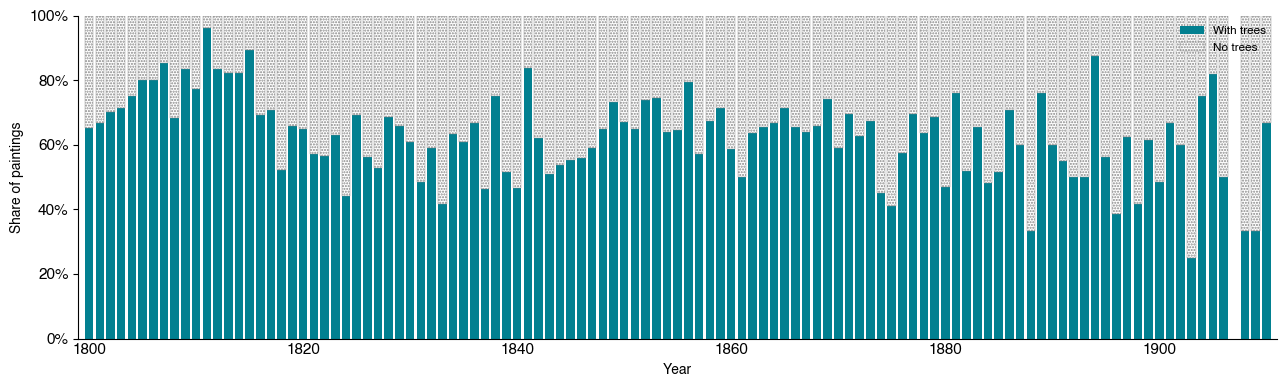

In [ ]:
# 100% stacked bar: tree vs no-tree paintings, year by year 
df_yr = df[df['year'].notna()].copy()
df_yr['year'] = df_yr['year'].astype(int)

paint_yr = (
    df_yr.groupby('year')
    .agg(n_tree=('has_tree', 'sum'),
         n_total=('has_tree', 'count'))
    .reset_index()
)
paint_yr['n_notree']   = paint_yr['n_total'] - paint_yr['n_tree']
paint_yr['pct_tree']   = paint_yr['n_tree']   / paint_yr['n_total'] * 100
paint_yr['pct_notree'] = paint_yr['n_notree'] / paint_yr['n_total'] * 100

fig, ax = plt.subplots(figsize=(13, 4))
yr_vals = paint_yr['year'].values

ax.bar(yr_vals, paint_yr['pct_tree'], width=0.8,
       color=COLOR_BAR, edgecolor='none', label='With trees')
ax.bar(yr_vals, paint_yr['pct_notree'], width=0.8,
       bottom=paint_yr['pct_tree'],
       color='white', edgecolor="#878787", hatch='......', linewidth=0.3,
       label='No trees')

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: str(int(y)) + '%'))
ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Share of paintings', fontsize=10)
ax.set_xlim(yr_vals.min() - 1, yr_vals.max() + 1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', length=0)
ax.legend(frameon=False, fontsize=8.5, loc='upper right')

plt.tight_layout()
plt.savefig('fig_paintings_norm_yearly.pdf', dpi=150, bbox_inches='tight')
plt.show()


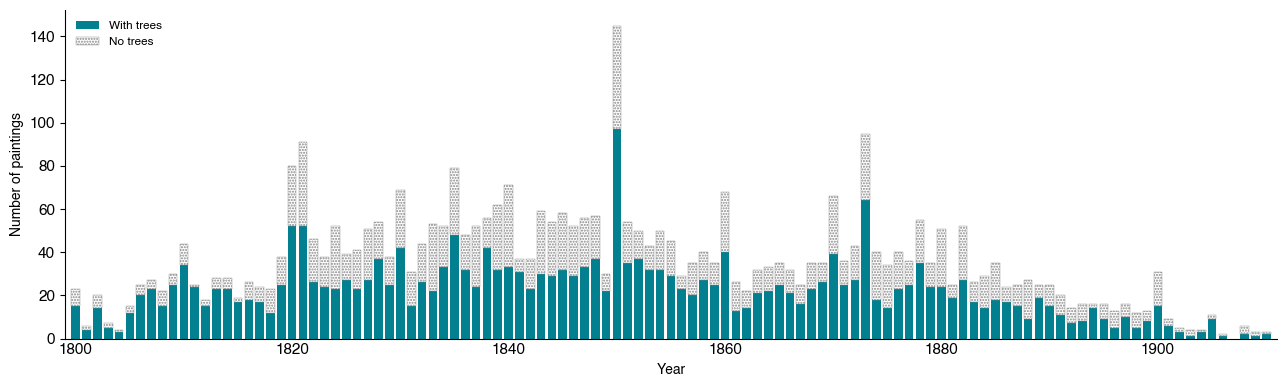

In [ ]:
# Absolute stacked bar: tree vs no-tree paintings, year by year 
fig, ax = plt.subplots(figsize=(13, 4))

ax.bar(yr_vals, paint_yr['n_tree'], width=0.8,
       color=COLOR_BAR, edgecolor='none', label='With trees')
ax.bar(yr_vals, paint_yr['n_notree'], width=0.8,
       bottom=paint_yr['n_tree'],
       color='white', edgecolor='#878787', hatch='......', linewidth=0.3,
       label='No trees')

ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Number of paintings', fontsize=10)
ax.set_xlim(yr_vals.min() - 1, yr_vals.max() + 1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', length=0)
ax.legend(frameon=False, fontsize=8.5, loc='upper left')

plt.tight_layout()
plt.savefig('fig_paintings_abs_yearly.pdf', dpi=150, bbox_inches='tight')
plt.show()


## relative space occupancy
Proportion of the canvas covered by tree masks.

In [43]:
df_occ = df[df['has_tree'] & df['mask_occupancy'].notna()].copy()
print(f'Tree paintings with occupancy data: {len(df_occ):,}')
print(f'Mean occupancy:   {df_occ["mask_occupancy"].mean():.3f}')
print(f'Median occupancy: {df_occ["mask_occupancy"].median():.3f}')
print(f'Stdev:            {df_occ["mask_occupancy"].std():.3f}')

# Classify by occupancy
bins   = [0, 0.05, 0.15, 0.35, 1.01]
labels = ['Minimal (<5%)', 'Low (5–15%)', 'Medium (15–35%)', 'High (>35%)']
df_occ['occ_bin'] = pd.cut(df_occ['mask_occupancy'], bins=bins, labels=labels)
print('\nOccupancy distribution:')
display(df_occ['occ_bin'].value_counts().sort_index().to_string())

Tree paintings with occupancy data: 2,905
Mean occupancy:   0.146
Median occupancy: 0.115
Stdev:            0.129

Occupancy distribution:


'occ_bin\nMinimal (<5%)      831\nLow (5–15%)        908\nMedium (15–35%)    910\nHigh (>35%)        256'

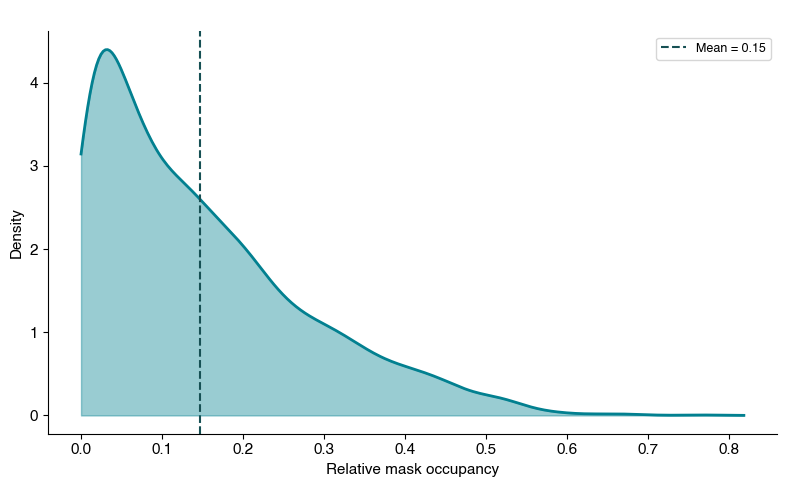

In [44]:
#plot it
from scipy.stats import gaussian_kde

x     = df_occ['mask_occupancy'].dropna().values
kde   = gaussian_kde(x)
x_rng = np.linspace(0, x.max() + 0.05, 300)

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(x_rng, kde(x_rng), alpha=0.4, color=COLOR_BAR)
ax.plot(x_rng, kde(x_rng), color=COLOR_BAR, lw=2)
ax.axvline(x.mean(), ls='--', color=COLOR_LINE, lw=1.5,
           label=f'Mean = {x.mean():.2f}')
ax.set_xlabel('Relative mask occupancy')
ax.set_ylabel('Density')
ax.set_title(' ')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{FIGS}/fig_occupancy.pdf')
plt.show()

## spatial distribution

Where on the canvas: Centroid coordinates (x = horizontal, y = vertical) are extracted from the masks. The scatter plot shows all detected tree centroids across the corpus, coloured by decade to reveal any compositional shifts over time.


In [45]:
df_cents_filt = df_cents[df_cents['year'].notna()].copy()
df_cents_filt['cy_inv'] = 1 - df_cents_filt['cy']   # 1 = foreground (bottom of canvas)

print(f'Tree centroids (dated): {len(df_cents_filt):,}')
print(f'Mean horizontal position (cx): {df_cents_filt["cx"].mean():.3f}  (0.5 = center)')
print(f'Mean vertical position (cy):   {df_cents_filt["cy"].mean():.3f}  (0=top, 1=bottom)')

# Horizontal and vertical
df_cents_filt['h_third'] = pd.cut(df_cents_filt['cx'],
                                   bins=[0, 1/3, 2/3, 1.001],
                                   labels=['Left', 'Center', 'Right'])
df_cents_filt['v_half']  = pd.cut(df_cents_filt['cy'],
                                   bins=[0, 0.5, 1.001],
                                   labels=['Upper (background)', 'Lower (foreground)'])

print('\nHorizontal placement:')
display((df_cents_filt['h_third'].value_counts(normalize=True) * 100).round(1).to_string())
print('\nVertical placement:')
display((df_cents_filt['v_half'].value_counts(normalize=True) * 100).round(1).to_string())

Tree centroids (dated): 21,544
Mean horizontal position (cx): 0.490  (0.5 = center)
Mean vertical position (cy):   0.532  (0=top, 1=bottom)

Horizontal placement:


'h_third\nLeft      35.3\nRight     32.6\nCenter    32.1'


Vertical placement:


'v_half\nLower (foreground)    61.2\nUpper (background)    38.8'

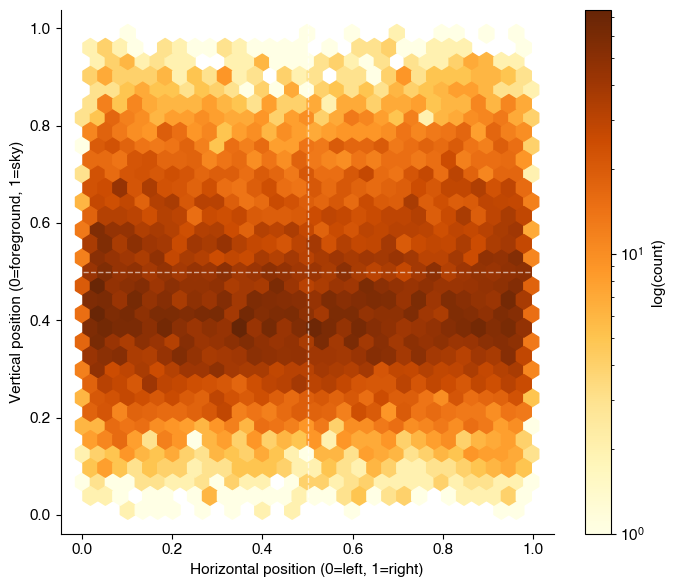

In [46]:
#plot it heatmap
fig, ax = plt.subplots(figsize=(7, 6))

hb = ax.hexbin(
    df_cents_filt['cx'], df_cents_filt['cy_inv'],
    gridsize=30, cmap='YlOrBr', bins='log'
)
ax.set_xlabel('Horizontal position (0=left, 1=right)')
ax.set_ylabel('Vertical position (0=foreground, 1=sky)')
ax.set_title('')
plt.colorbar(hb, ax=ax, label='log(count)')
ax.axhline(0.5, ls='--', color='white', lw=1, alpha=0.6)
ax.axvline(0.5, ls='--', color='white', lw=1, alpha=0.6)

plt.tight_layout()
plt.savefig(f'{FIGS}/fig_spatial_heatmap.pdf')
plt.show()

## simple color

Compares low-level colour properties of tree pixels against the surrounding canvas. For each painting, brightness, greenness, warmth, and saturation are computed separately for (a) pixels inside the tree mask and (b) all remaining canvas pixels. The delta (tree − canvas) is averaged across the corpus.


In [47]:
def image_color_stats(jpeg_bytes):
    """Return dict of color/texture stats from JPEG bytes (via 64×64 thumbnail)."""
    try:
        img = Image.open(io.BytesIO(jpeg_bytes)).convert('RGB').resize((64, 64))
        a   = np.array(img, dtype=np.float32) / 255.0   # (64, 64, 3)
        r, g, b = a[:,:,0], a[:,:,1], a[:,:,2]

        # Pixelwise HSV
        cmax  = np.maximum(np.maximum(r, g), b)
        cmin  = np.minimum(np.minimum(r, g), b)
        delta = cmax - cmin

        # Saturation
        sat = np.where(cmax > 0, delta / cmax, 0)

        # Hue in [0, 360]
        hue = np.zeros_like(r)
        mr = (cmax == r) & (delta > 0)
        mg = (cmax == g) & (delta > 0)
        mb = (cmax == b) & (delta > 0)
        hue[mr] = (60 * ((g[mr] - b[mr]) / delta[mr])) % 360
        hue[mg] =  60 * ((b[mg] - r[mg]) / delta[mg] + 2)
        hue[mb] =  60 * ((r[mb] - g[mb]) / delta[mb] + 4)

        greenness = g.mean() - (r.mean() + b.mean()) / 2
        warmth    = r.mean() - b.mean()

        return {
            'brightness': float(cmax.mean()),
            'saturation': float(sat.mean()),
            'mean_hue':   float(hue.mean()),
            'greenness':  float(greenness),
            'warmth':     float(warmth),
            'contrast':   float(cmax.std()),   
        }
    except:
        return None

print('Computing color statistics…')
color_rows = []
for i, (_, row) in enumerate(df.iterrows()):
    if i % 500 == 0: print(f'  {i}/{len(df)}')
    stats = image_color_stats(row['image'])
    if stats:
        color_rows.append({
            'year': row['year'], 'decade': row['decade'],
            'has_tree': row['has_tree'],
            'painting_type': row.get('painting_type', None),
            **stats
        })

df_color = pd.DataFrame(color_rows)
print(f'Done. Color stats for {len(df_color):,} paintings.')

Computing color statistics…
  0/4616
  500/4616
  1000/4616
  1500/4616
  2000/4616
  2500/4616
  3000/4616
  3500/4616
  4000/4616
  4500/4616
Done. Color stats for 4,616 paintings.


Computed color stats for 600 paintings across 6 nationalities


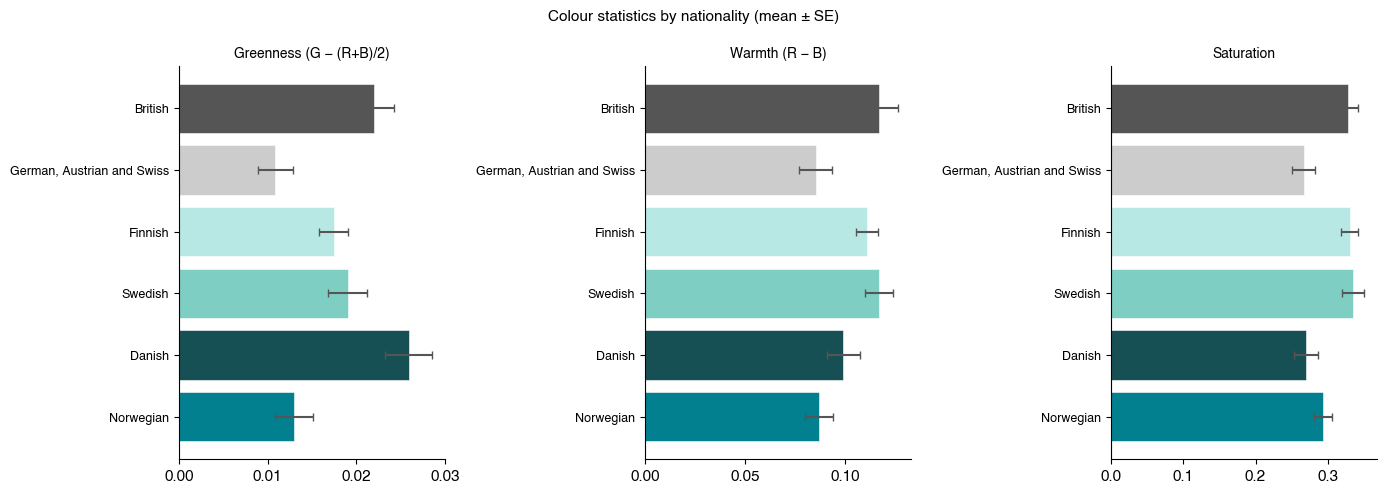

In [49]:
# Colour by nationality
# Samples up to 100 paintings per nationality

nat_color_rows = []
for nat in col_order:
    sub = df[df['Artist-nationality'] == nat]
    sample = sub.sample(min(len(sub), 100), random_state=42) if len(sub) > 0 else sub
    for _, row in sample.iterrows():
        try:
            stats = image_color_stats(row['image'])
            if stats:
                nat_color_rows.append({'nationality': nat, **stats})
        except: pass

df_nc = pd.DataFrame(nat_color_rows)
print(f'Computed color stats for {len(df_nc)} paintings across {df_nc["nationality"].nunique()} nationalities')

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
metrics = [('greenness',  'Greenness (G − (R+B)/2)'),
           ('warmth',     'Warmth (R − B)'),
           ('saturation', 'Saturation')]

for ax, (metric, title) in zip(axes, metrics):
    means = df_nc.groupby('nationality')[metric].mean().reindex(col_order).dropna()
    sems  = df_nc.groupby('nationality')[metric].sem().reindex(col_order).dropna()
    bar_colors = [nat_colors.get(n, '#888') for n in means.index]
    ax.barh(range(len(means)), means.values, color=bar_colors,
            edgecolor='white', lw=0.4,
            xerr=sems.values, error_kw={'ecolor': '#555', 'capsize': 3})
    ax.set_yticks(range(len(means)))
    ax.set_yticklabels(means.index, fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.axvline(0, color='grey', lw=0.8, ls='--')

plt.suptitle('Colour statistics by nationality (mean ± SE)', fontsize=11)
plt.tight_layout()
plt.savefig(f'{FIGS}/fig_color_nationality.pdf')
plt.show()

Processed 2904 paintings


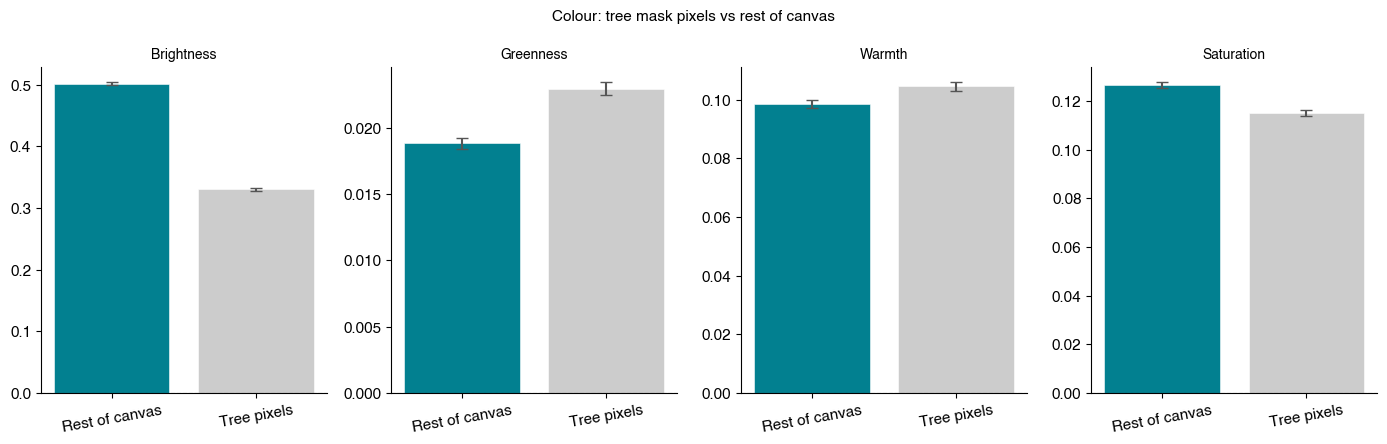

In [50]:
# Colour in tree mask regions vs the rest
# note that this processes ALL tree paintings; expect 15-20 min

mask_region_rows = []
df_tree_sample = df[df['has_tree']].copy()

for _, row in df_tree_sample.iterrows():
    mask_bytes = row.get('mask')
    if not isinstance(mask_bytes, (bytes, bytearray)) or len(mask_bytes) == 0:
        continue
    try:
        npz   = np.load(io.BytesIO(mask_bytes), allow_pickle=True)
        masks = npz['masks']
        if masks.ndim != 4 or masks.shape[0] == 0: continue
        _, _, H, W = masks.shape
        union = masks[:, 0].any(axis=0)

        img = Image.open(io.BytesIO(row['image'])).convert('RGB').resize((W, H))
        a   = np.array(img, dtype=np.float32) / 255.0

        def pix_stats(px):
            r, g, b = px[:,0], px[:,1], px[:,2]
            return {'brightness': float(np.maximum(np.maximum(r,g),b).mean()),
                    'greenness':  float(g.mean() - (r.mean()+b.mean())/2),
                    'warmth':     float(r.mean() - b.mean()),
                    'saturation': float((np.maximum(np.maximum(r,g),b) -
                                         np.minimum(np.minimum(r,g),b)).mean())}

        tree_px    = a[union].reshape(-1, 3)
        nontree_px = a[~union].reshape(-1, 3)
        if len(tree_px) < 50 or len(nontree_px) < 50: continue

        mask_region_rows.append({'region': 'Tree pixels',    **pix_stats(tree_px)})
        mask_region_rows.append({'region': 'Rest of canvas', **pix_stats(nontree_px)})
    except: pass

df_mr = pd.DataFrame(mask_region_rows)
print(f'Processed {len(df_mr)//2} paintings')

fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))
for ax, metric in zip(axes, ['brightness', 'greenness', 'warmth', 'saturation']):
    means = df_mr.groupby('region')[metric].mean()
    sems  = df_mr.groupby('region')[metric].sem()
    ax.bar(means.index, means.values, color=[COLOR_BAR, '#cccccc'],
           edgecolor='white', lw=0.4,
           yerr=sems.values, error_kw={'ecolor': '#555', 'capsize': 4})
    ax.set_title(metric.capitalize(), fontsize=10)
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.tick_params(axis='x', labelrotation=10)

plt.suptitle('Colour: tree mask pixels vs rest of canvas', fontsize=11)
plt.tight_layout()
plt.savefig(f'{FIGS}/fig_color_mask_regions.pdf')
plt.show()


nationality
British                       100
Danish                        100
Finnish                       100
German, Austrian and Swiss    100
Norwegian                     100
Swedish                        94


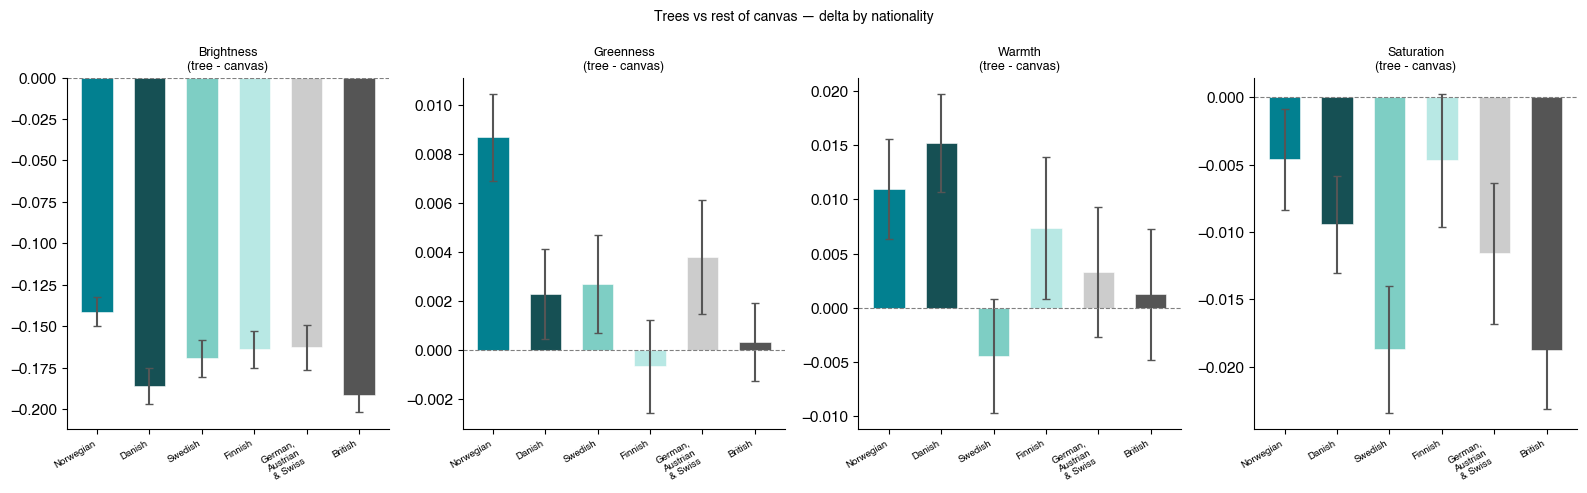

In [51]:
#  tree pixels vs rest of canvas by nationality
# Delta (tree - canvas)
# Samples 100 tree paintings per nationality.

nat_mask_rows = []
for nat in col_order:
    subset = df[df['has_tree'] & df['Artist-nationality'].eq(nat)]
    if len(subset) == 0: continue
    sample = subset.sample(min(100, len(subset)), random_state=42)
    for _, row in sample.iterrows():
        mask_bytes = row.get('mask')
        if not isinstance(mask_bytes, (bytes, bytearray)) or len(mask_bytes) == 0:
            continue
        try:
            npz   = np.load(io.BytesIO(mask_bytes), allow_pickle=True)
            masks = npz['masks']
            if masks.ndim != 4 or masks.shape[0] == 0: continue
            _, _, H, W = masks.shape
            union = masks[:, 0].any(axis=0)
            img = Image.open(io.BytesIO(row['image'])).convert('RGB').resize((W, H))
            a   = np.array(img, dtype=np.float32) / 255.0
            tree_px    = a[union].reshape(-1, 3)
            nontree_px = a[~union].reshape(-1, 3)
            if len(tree_px) < 50 or len(nontree_px) < 50: continue

            def _ps(px):
                r, g, b = px[:,0], px[:,1], px[:,2]
                return {'brightness': float(np.maximum(np.maximum(r,g),b).mean()),
                        'greenness':  float(g.mean() - (r.mean()+b.mean())/2),
                        'warmth':     float(r.mean() - b.mean()),
                        'saturation': float((np.maximum(np.maximum(r,g),b) -
                                             np.minimum(np.minimum(r,g),b)).mean())}

            ts = _ps(tree_px)
            ns = _ps(nontree_px)
            nat_mask_rows.append({
                'nationality': nat,
                **{f'delta_{k}': ts[k] - ns[k] for k in ts},
            })
        except: pass

df_nat_mask = pd.DataFrame(nat_mask_rows)
print(df_nat_mask.groupby('nationality').size().rename('n paintings').to_string())

metrics  = ['brightness', 'greenness', 'warmth', 'saturation']
nat_clrs = {nat: info['color'] for nat, info in CATEGORIES.items()}
x = np.arange(len(col_order))

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, metric in zip(axes, metrics):
    col   = f'delta_{metric}'
    grp   = df_nat_mask.groupby('nationality')[col]
    means = [grp.get_group(n).mean() if n in grp.groups else np.nan for n in col_order]
    sems  = [grp.get_group(n).sem()  if n in grp.groups else 0      for n in col_order]
    colors = [nat_clrs.get(n, '#888') for n in col_order]
    ax.bar(x, means, width=0.6, color=colors, edgecolor='white', lw=0.4,
           yerr=sems, error_kw={'ecolor': '#555', 'capsize': 3})
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace(' and ', '\n& ').replace(', ', ',\n')
                        for n in col_order], fontsize=7, rotation=30, ha='right')
    ax.set_title(f'{metric.capitalize()}\n(tree - canvas)', fontsize=9)

plt.suptitle('Trees vs rest of canvas — delta by nationality', fontsize=10)
plt.tight_layout()
plt.savefig(f'{FIGS}/fig_color_mask_nationality.pdf')
plt.show()


Computed delta brightness for 200 paintings
Most negative (dark tree on bright canvas): -0.567
Most positive (bright tree on dark canvas): 0.193


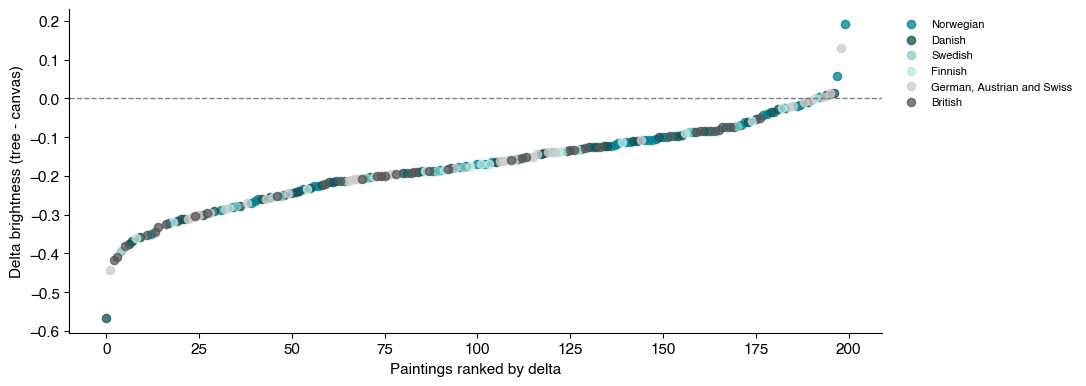

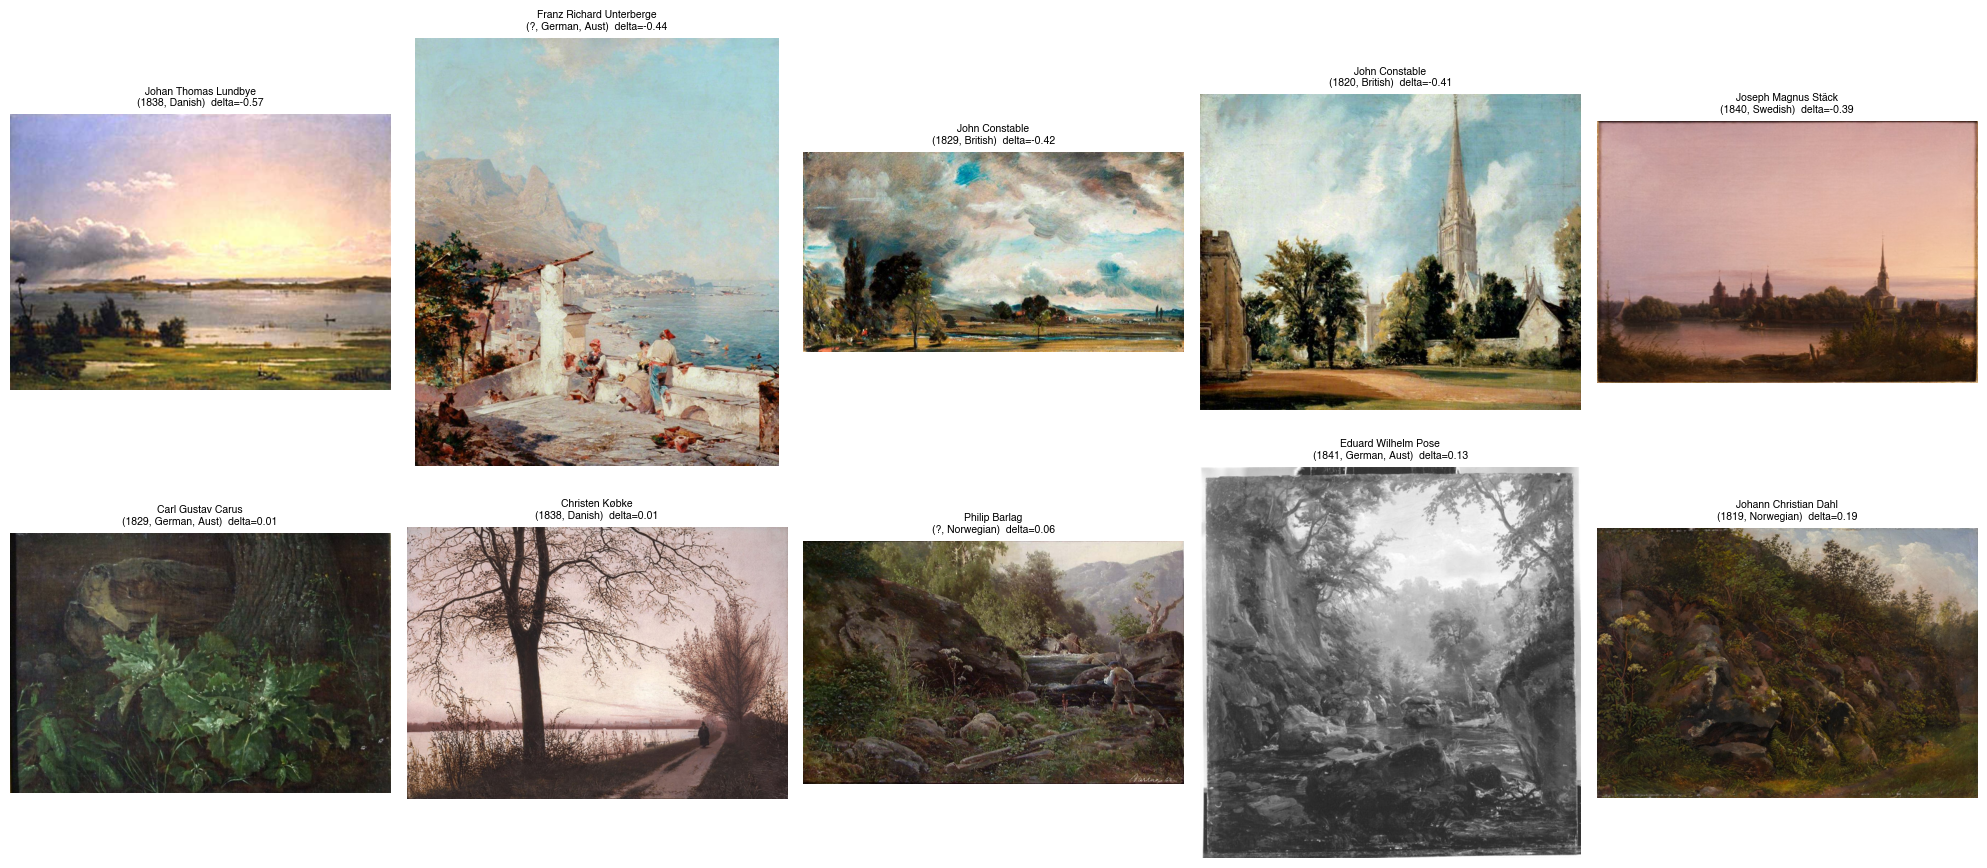

In [52]:
# Brightness contrast: tree vs surrounding canvas
# Ranks paintings by delta brightness

N_SAMPLE = 200
N_SHOW   = 5

contrast_rows = []
df_tree_sample = df[df['has_tree']].sample(min(N_SAMPLE, int(df['has_tree'].sum())), random_state=99)

for _, row in df_tree_sample.iterrows():
    mask_bytes = row.get('mask')
    if not isinstance(mask_bytes, (bytes, bytearray)) or len(mask_bytes) == 0:
        continue
    try:
        npz   = np.load(io.BytesIO(mask_bytes), allow_pickle=True)
        masks = npz['masks']
        if masks.ndim != 4 or masks.shape[0] == 0: continue
        _, _, H, W = masks.shape
        union = masks[:, 0].any(axis=0)

        img = Image.open(io.BytesIO(row['image'])).convert('RGB').resize((W, H))
        a   = np.array(img, dtype=np.float32) / 255.0

        tree_px   = a[union].reshape(-1, 3)
        canvas_px = a[~union].reshape(-1, 3)
        if len(tree_px) < 50 or len(canvas_px) < 50: continue

        tree_bright   = np.max(tree_px,   axis=1).mean()
        canvas_bright = np.max(canvas_px, axis=1).mean()

        contrast_rows.append({
            'delta':         tree_bright - canvas_bright,
            'tree_bright':   tree_bright,
            'canvas_bright': canvas_bright,
            'artist':        row['artist'],
            'year':          row['year'],
            'nationality':   row['Artist-nationality'],
            'n_trees':       row['count'],
            'img_bytes':     row['image'],
        })
    except: pass

df_contrast = (pd.DataFrame(contrast_rows)
               .dropna(subset=['delta'])
               .sort_values('delta')
               .reset_index(drop=True))
print(f'Computed delta brightness for {len(df_contrast)} paintings')
print(f'Most negative (dark tree on bright canvas): {df_contrast["delta"].min():.3f}')
print(f'Most positive (bright tree on dark canvas): {df_contrast["delta"].max():.3f}')

# Scatterplot
fig, ax = plt.subplots(figsize=(11, 4))
for nat in col_order:
    sub = df_contrast[df_contrast['nationality'] == nat]
    if len(sub) == 0: continue
    ax.scatter(sub.index, sub['delta'].values,
               color=nat_colors.get(nat, '#888'), label=nat, alpha=0.75, s=35)
ax.axhline(0, ls='--', color='grey', lw=1)
ax.set_xlabel('Paintings ranked by delta')
ax.set_ylabel('Delta brightness (tree - canvas)')
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{FIGS}/fig_contrast_scatter.pdf')
plt.show()

# Full paintings examples
fig, axes = plt.subplots(2, N_SHOW, figsize=(N_SHOW * 4, 9))
for row_i, (label, subset) in enumerate([
    ('Dark tree on bright canvas', df_contrast.head(N_SHOW)),
    ('Bright tree on dark canvas', df_contrast.tail(N_SHOW)),
]):
    for col_i, (_, r) in enumerate(subset.iterrows()):
        ax = axes[row_i, col_i]
        img = Image.open(io.BytesIO(r['img_bytes']))
        img.thumbnail((600, 600))
        ax.imshow(img)
        year = int(r['year']) if pd.notna(r['year']) else '?'
        ax.set_title(
            f"{str(r['artist'])[:24]}\n({year}, {str(r['nationality'])[:12]})  delta={r['delta']:.2f}",
            fontsize=7.5
        )
        ax.axis('off')
    axes[row_i, 0].set_ylabel(label, fontsize=9, labelpad=8)

plt.tight_layout()
plt.savefig(f'{FIGS}/fig_contrast_paintings.pdf')
plt.show()


In [ ]:
# ── Push notebook to GitHub ──────────────────────────────────────────────────
# Run this cell from the project root after making changes.
import subprocess

commands = [
    ['git', 'add', 'CHREADH.ipynb', 'README.md', '.gitignore'],
    ['git', 'commit', '-m', 'Add detection analysis notebook and README'],
    ['git', 'push', 'origin', 'main'],
]

for cmd in commands:
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(' '.join(cmd))
    if result.stdout: print(result.stdout.strip())
    if result.stderr: print(result.stderr.strip())
    print()
